# Plot Channel-Level Expected Scaling

This notebook reads channel-scaling checkpoints from `scaling/data/` and plots only the expected step counts:

- NCC expected
- HNCC expected

The output is `figures/scaling_channel_expected.pdf`. The loader accepts both sampling checkpoints with `expected_r_mins` and expected-only checkpoints with `expected_r_min`, such as `NCC_channel_log_expected_r_min_N8_T2_eps0.01_q4_s4.json`.


In [3]:
import json
import math
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

%config InlineBackend.figure_format = 'retina'
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams['text.usetex'] = False
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['mathtext.rm'] = 'STIXGeneral'
plt.rcParams['mathtext.it'] = 'STIXGeneral:italic'
plt.rcParams['mathtext.bf'] = 'STIXGeneral:bold'
plt.rcParams['pdf.fonttype'] = 3

FIGSIZE = (10.8, 3.55)
TITLE_SIZE = 10
LABEL_SIZE = 10
TICK_SIZE = 8.5
LEGEND_SIZE = 10.0
LINEWIDTH = 1.5
MARKER_SIZE = 3.6

SAVE_PDF = True
# Plot the unconstrained expected precision curve as the fitted primary series.
PLOT_PRECISION_ONLY = True
# Whether to connect the hollow, 1-norm-constrained markers.
CONNECT_ONE_NORM_CONSTRAINED = False
OUTPUT_STEM = 'scaling_channel_expected' if PLOT_PRECISION_ONLY else 'scaling_channel_expected_raw'


def find_scaling_dir():
    for candidate in (Path.cwd(), Path.cwd() / 'scaling', Path.cwd().parent / 'scaling'):
        if (candidate / 'data').is_dir():
            return candidate.resolve()
    raise FileNotFoundError('Could not locate scaling/data from the current working directory.')


SCALING_DIR = find_scaling_dir()
REPO_ROOT = SCALING_DIR.parent
FIG_DIR = REPO_ROOT / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = SCALING_DIR / 'data'

BASELINE = {
    'N': 8,
    'T': 2.0,
    'epsilon': 0.001,
}
EPSILON_TARGETS = [0.1, 0.04, 0.02, 0.01, 0.005, 0.0025, 0.001]
SWEEP_TARGETS = {
    'N': [4, 6, 8],
    'T': [0.2, 0.4, 0.6, 0.8, 1.0, 2.0],
    'inv_epsilon': [float(1.0 / eps) for eps in EPSILON_TARGETS],
}

MODE_STYLE = {
    'original': {'label': 'NCC expected', 'color': '#1f77b4', 'marker': 'o'},
    'log': {'label': 'HNCC expected', 'color': '#d62728', 'marker': 'D'},
}

# Higher priority records are preferred when several files describe the same point.
RESULT_SOURCES = [
    ('original', 4, 'NCC_channel_original_expected_r_min_*.json'),
    ('log', 4, 'NCC_channel_log_expected_r_min_*.json'),
    ('log', 3, 'NCC_channel_log_sampling_r_*.json'),
    ('original', 3, 'NCC_channel_original_sampling_r_*.json'),
    # Legacy operator-version data; retained on disk but never used as a fallback.
    # ('original', 2, 'NCC_original_sampling_r_*.json'),
]
ORIGINAL_EXPECTED_PARTIAL_PATH = DATA_DIR / 'archive' / 'NCC_channel_original_expected_r_min_N8_T2_bohrium_partial_20260710.json'

OVERHEAD_FLOOR_EXPECTED = True
# Must match the cap encoded by the active overhead tables below (currently cap_1p75).
ONE_NORM_UPPER_BOUND = 1.75
ONE_NORM_UPPER_BOUND_LABEL = 'e' if math.isclose(ONE_NORM_UPPER_BOUND, math.e) else f'{ONE_NORM_UPPER_BOUND:g}'
OVERHEAD_RMIN_PATH = REPO_ROOT / '1-norm' / 'pauli_sampling_overhead_rmin_N8_cap_1p75.csv'
OVERHEAD_RMIN_N_SWEEP_PATH = REPO_ROOT / '1-norm' / 'pauli_sampling_overhead_rmin_N_sweep_T2_cap_1p75.csv'


def load_overhead_rmin_table(path):
    table = np.genfromtxt(path, delimiter=',', names=True)
    table = np.atleast_1d(table)
    rows = {}
    for row in table:
        rows[round(float(row['T']), 12)] = {
            'original': float(row['original_channel']),
            'log': float(row['log_channel_s4']),
        }
    return rows


OVERHEAD_RMIN_BY_T = load_overhead_rmin_table(OVERHEAD_RMIN_PATH)


def load_overhead_n_sweep_table(path):
    table = np.genfromtxt(path, delimiter=',', names=True)
    table = np.atleast_1d(table)
    rows = {}
    for row in table:
        rows[int(round(float(row['N'])))] = {
            'original': float(row['original_channel']),
            'log': float(row['log_channel_s4']),
        }
    return rows


OVERHEAD_RMIN_BY_N = load_overhead_n_sweep_table(OVERHEAD_RMIN_N_SWEEP_PATH)


def lookup_overhead_rmin(T, mode):
    for table_T, row in OVERHEAD_RMIN_BY_T.items():
        if math.isclose(float(T), table_T, rel_tol=0.0, abs_tol=1e-12):
            return row[mode]
    available = ', '.join(f'{T:g}' for T in sorted(OVERHEAD_RMIN_BY_T))
    raise ValueError(f'No Pauli-sampling overhead nu_min for t={T}; available t values: {available}')


def lookup_overhead_n_rmin(N, mode):
    n_key = int(round(float(N)))
    row = OVERHEAD_RMIN_BY_N.get(n_key)
    if row is None:
        return 0.0
    return row[mode]


def expected_overhead_floor(axis_key, x_value, mode):
    if not OVERHEAD_FLOOR_EXPECTED:
        return 0.0
    if axis_key == 'N':
        return float(lookup_overhead_n_rmin(float(x_value), mode))
    if axis_key == 'T':
        return float(lookup_overhead_rmin(float(x_value), mode))
    if axis_key == 'inv_epsilon':
        return float(lookup_overhead_rmin(float(BASELINE['T']), mode))
    return 0.0


def format_tick_labels(values):
    labels = []
    for value in np.array(values, dtype=float):
        if math.isclose(value, round(value), abs_tol=1e-12):
            labels.append(str(int(round(value))))
        else:
            labels.append(f'{value:.2f}'.rstrip('0').rstrip('.'))
    return labels


Y_TICKS = np.array([20.0, 40.0, 100.0, 200.0, 400.0, 600.0], dtype=float)


def configure_log_ticks(ax, x_values, y_ticks=Y_TICKS, rotate_x=False):
    x_values = np.array(sorted(set(np.asarray(x_values, dtype=float))), dtype=float)
    if x_values.size:
        ax.xaxis.set_major_locator(mticker.FixedLocator(x_values))
        ax.xaxis.set_major_formatter(mticker.FixedFormatter(format_tick_labels(x_values)))
    y_ticks = np.asarray(y_ticks, dtype=float)
    ax.yaxis.set_major_locator(mticker.FixedLocator(y_ticks))
    ax.yaxis.set_major_formatter(mticker.FixedFormatter(format_tick_labels(y_ticks)))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    if rotate_x:
        ax.tick_params(axis='x', labelrotation=0)
    ax.tick_params(axis='both', labelsize=TICK_SIZE)


def apply_center_limits(ax, x_values, y_values):
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)
    if x_values.size == 1:
        ax.set_xlim(float(x_values[0] / 1.2), float(x_values[0] * 1.2))
    else:
        ax.set_xlim(float(np.min(x_values) / 1.08), float(np.max(x_values) * 1.08))
    y_min = float(np.nanmin(y_values))
    y_max = float(np.nanmax(y_values))
    ax.set_ylim(y_min / 1.08, y_max * 1.08)


def plot_missing(ax, title, xlabel):
    ax.set_title(title, fontsize=TITLE_SIZE)
    ax.set_xlabel(xlabel, fontsize=LABEL_SIZE)
    ax.text(0.5, 0.5, 'data not collected', ha='center', va='center', fontsize=LABEL_SIZE, transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_alpha(0.3)


def expected_value(payload):
    if 'expected_r_min' in payload:
        value = payload.get('expected_r_min')
        if value is not None and float(value) >= 0:
            return float(value)
    values = np.asarray(payload.get('expected_r_mins', []), dtype=float)
    values = values[np.isfinite(values) & (values >= 0)]
    if values.size:
        return float(values.mean())
    return float('nan')


def parse_checkpoint(path, mode, priority):
    if 'smoke' in path.parts or 'smoke' in path.stem.lower():
        return None
    payload = json.loads(path.read_text())
    params = payload.get('params', {})
    # Older expected-only files keep N/T/epsilon at top level rather than under params.
    if not params and all(key in payload for key in ('N', 'T', 'epsilon')):
        params = {key: payload[key] for key in ('N', 'T', 'epsilon')}
    if not params:
        return None
    value = expected_value(payload)
    if not np.isfinite(value):
        return None
    epsilon = float(params['epsilon'])
    repeats = int(params.get('repeats', params.get('requested_repeats', 1)))
    trials = int(params.get('trials', 0))
    return {
        'path': path,
        'mode': mode,
        'priority': priority,
        'N': int(params['N']),
        'T': float(params['T']),
        'epsilon': epsilon,
        'inv_epsilon': float(1.0 / epsilon),
        'trials': trials,
        'repeats': repeats,
        'expected': value,
    }


def load_original_partial_expected_records(path, priority=5):
    if not path.exists():
        return []
    payload = json.loads(path.read_text())
    params = payload.get('params', {})
    records = []
    for case in payload.get('cases', []):
        interval = case.get('plot_expected_r_interval') or case.get('estimated_expected_r_min_interval')
        adopted = case.get('adopted_expected_r_min')
        if interval is None and adopted is not None:
            interval = [float(adopted), float(adopted)]
        if interval is None:
            continue
        low, high = [float(v) for v in interval]
        center = 0.5 * (low + high)
        epsilon = float(case['epsilon'])
        records.append({
            'path': path,
            'mode': 'original',
            'priority': priority,
            'N': int(params.get('N', BASELINE['N'])),
            'T': float(params.get('T', BASELINE['T'])),
            'epsilon': epsilon,
            'inv_epsilon': float(1.0 / epsilon),
            'trials': 0,
            'repeats': 1,
            'expected': center,
            'expected_interval': (low, high),
            'source_case': case,
        })
    return records


records = []
for mode, priority, pattern in RESULT_SOURCES:
    for path in sorted(DATA_DIR.rglob(pattern)):
        record = parse_checkpoint(path, mode, priority)
        if record is not None:
            records.append(record)
# Temporarily disabled: partial intervals must not override completed expected-only records.
# records.extend(load_original_partial_expected_records(ORIGINAL_EXPECTED_PARTIAL_PATH))

if not records:
    raise RuntimeError(f'No expected channel-scaling records found under {DATA_DIR}.')


def choose_best(records_for_same_point):
    return max(records_for_same_point, key=lambda item: (item['priority'], item['repeats'], item['trials']))


def collect_series(axis_key, include_overhead_floor=True):
    grouped = defaultdict(list)
    for record in records:
        if axis_key == 'N':
            if not math.isclose(record['T'], BASELINE['T'], rel_tol=0.0, abs_tol=1e-12) or not math.isclose(record['epsilon'], BASELINE['epsilon'], rel_tol=0.0, abs_tol=1e-12):
                continue
            x_value = record['N']
        elif axis_key == 'T':
            if record['N'] != BASELINE['N'] or not math.isclose(record['epsilon'], BASELINE['epsilon'], rel_tol=0.0, abs_tol=1e-12):
                continue
            x_value = record['T']
        elif axis_key == 'inv_epsilon':
            if record['N'] != BASELINE['N'] or not math.isclose(record['T'], BASELINE['T'], rel_tol=0.0, abs_tol=1e-12):
                continue
            x_value = record['inv_epsilon']
        else:
            raise ValueError(axis_key)
        grouped[(record['mode'], x_value)].append(record)

    series = defaultdict(list)
    for mode in MODE_STYLE:
        for target in SWEEP_TARGETS[axis_key]:
            items = grouped.get((mode, target), [])
            if items:
                item = choose_best(items)
                floor = expected_overhead_floor(axis_key, target, mode) if include_overhead_floor else 0.0
                y = max(item['expected'], floor)
                series[mode].append((target, y, item))
    return series


series_by_axis = {axis: collect_series(axis, include_overhead_floor=True) for axis in ('N', 'T', 'inv_epsilon')}
precision_series_by_axis = {axis: collect_series(axis, include_overhead_floor=False) for axis in ('N', 'T', 'inv_epsilon')}

print('loaded expected records:', len(records))
for axis in ('N', 'T', 'inv_epsilon'):
    for mode in MODE_STYLE:
        points = series_by_axis[axis].get(mode, [])
        print(axis, mode, [(x, y, item['path'].name) for x, y, item in points])
    if PLOT_PRECISION_ONLY:
        for mode in MODE_STYLE:
            points = precision_series_by_axis[axis].get(mode, [])
            print(axis, mode, 'precision_only', [(x, y, item['path'].name) for x, y, item in points])


loaded expected records: 42
N original [(4, 148.0, 'NCC_channel_original_sampling_r_N4_T2_eps0.001_trials1000_repeats10.json'), (6, 153.0, 'NCC_channel_original_sampling_r_N6_T2_eps0.001_trials1000_repeats10.json'), (8, 169.0, 'NCC_channel_original_expected_r_min_N8_T2_eps0.001.json')]
N log [(4, 58.0, 'NCC_channel_log_sampling_r_N4_T2_eps0.001_trials1000_repeats10_q4_s4.json'), (6, 73.0, 'NCC_channel_log_sampling_r_N6_T2_eps0.001_trials1000_repeats10_q4_s4.json'), (8, 86.0, 'NCC_channel_log_expected_r_min_N8_T2_eps0.001_q4_s4.json')]
N original precision_only [(4, 148.0, 'NCC_channel_original_sampling_r_N4_T2_eps0.001_trials1000_repeats10.json'), (6, 153.0, 'NCC_channel_original_sampling_r_N6_T2_eps0.001_trials1000_repeats10.json'), (8, 169.0, 'NCC_channel_original_expected_r_min_N8_T2_eps0.001.json')]
N log precision_only [(4, 58.0, 'NCC_channel_log_sampling_r_N4_T2_eps0.001_trials1000_repeats10_q4_s4.json'), (6, 58.0, 'NCC_channel_log_sampling_r_N6_T2_eps0.001_trials1000_repeats10_q

1-norm upper bound: 1.75


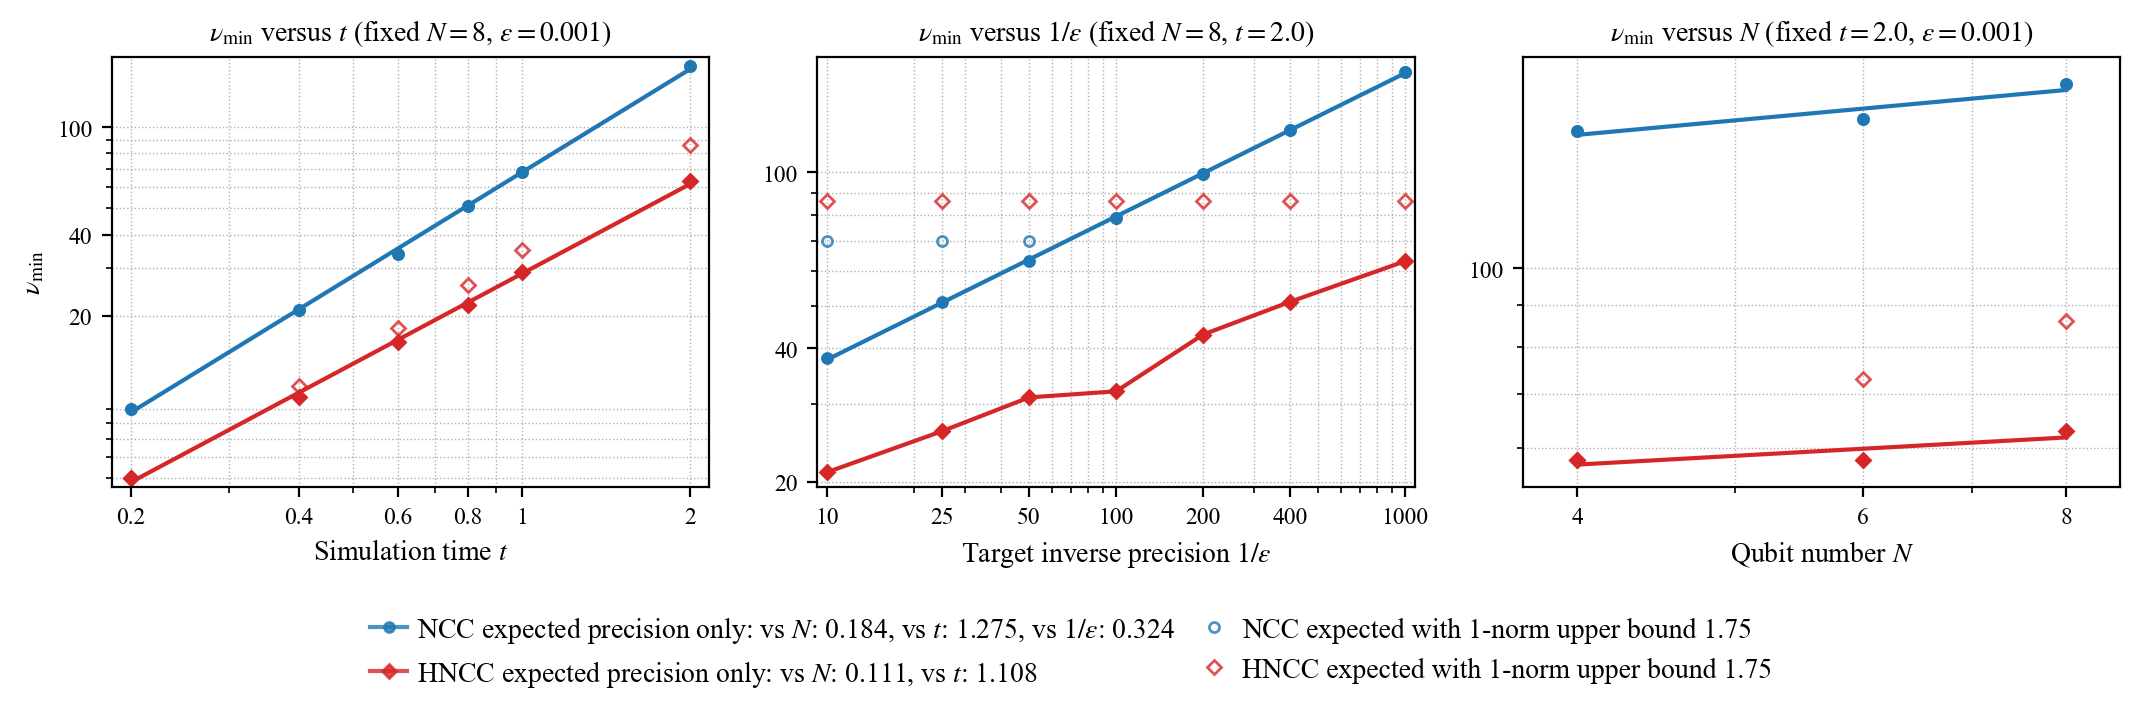

In [4]:
plt.close('all')

from matplotlib.lines import Line2D


def use_fit_line(axis_key, mode):
    if axis_key in ('N', 'T'):
        return True
    if axis_key == 'inv_epsilon' and mode == 'original':
        return True
    return False


def fit_power_law(xs, ys):
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    mask = (xs > 0) & (ys > 0) & np.isfinite(xs) & np.isfinite(ys)
    if np.count_nonzero(mask) < 2:
        return float('nan'), xs[mask], ys[mask]
    log_x = np.log(xs[mask])
    log_y = np.log(ys[mask])
    slope, intercept = np.polyfit(log_x, log_y, deg=1)
    x_fit = np.geomspace(float(np.min(xs[mask])), float(np.max(xs[mask])), 200)
    y_fit = np.exp(intercept) * x_fit**slope
    return float(slope), x_fit, y_fit


def format_slope_value(slope):
    if not np.isfinite(slope):
        return r'$-$'
    return f'{slope:.3f}'


def draw_expected(ax, xs, ys, style, fit_enabled):
    if fit_enabled:
        ax.plot(
            xs,
            ys,
            marker=style['marker'],
            linestyle='None',
            markersize=MARKER_SIZE,
            color=style['color'],
        )
        slope, x_fit, y_fit = fit_power_law(xs, ys)
        ax.plot(
            x_fit,
            y_fit,
            linestyle='-',
            linewidth=LINEWIDTH,
            color=style['color'],
        )
        return slope
    ax.plot(
        xs,
        ys,
        marker=style['marker'],
        linestyle='-',
        linewidth=LINEWIDTH,
        markersize=MARKER_SIZE,
        color=style['color'],
    )
    return None


def draw_one_norm_constrained(ax, xs, ys, style):
    ax.plot(
        xs,
        ys,
        marker=style['marker'],
        linestyle='-' if CONNECT_ONE_NORM_CONSTRAINED else 'None',
        linewidth=LINEWIDTH,
        markersize=MARKER_SIZE,
        color=style['color'],
        markerfacecolor='none',
        alpha=0.8,
    )


def draw_interval_errorbars(ax, xs, ys, points, style):
    err_xs = []
    err_ys = []
    lower = []
    upper = []
    for x, y, item in points:
        interval = item.get('expected_interval')
        if interval is None:
            continue
        low, high = [float(v) for v in interval]
        err_xs.append(float(x))
        err_ys.append(float(y))
        lower.append(max(0.0, float(y) - low))
        upper.append(max(0.0, high - float(y)))
    if not err_xs:
        return
    ax.errorbar(
        np.asarray(err_xs, dtype=float),
        np.asarray(err_ys, dtype=float),
        yerr=np.vstack([lower, upper]),
        fmt='none',
        ecolor=style['color'],
        elinewidth=LINEWIDTH * 0.9,
        capsize=2.2,
        capthick=LINEWIDTH * 0.8,
        alpha=0.85,
        zorder=4,
    )


def plot_expected_panel(ax, axis_key, axis_slope_label, xlabel, title, slope_entries, y_ticks=Y_TICKS):
    ax.set_xscale('log')
    ax.set_yscale('log')
    x_values = []
    y_values = []

    for mode, style in MODE_STYLE.items():
        if PLOT_PRECISION_ONLY:
            precision_points = precision_series_by_axis[axis_key].get(mode, [])
            if precision_points:
                precision_xs = np.array([x for x, _, _ in precision_points], dtype=float)
                precision_ys = np.array([y for _, y, _ in precision_points], dtype=float)
                slope = draw_expected(ax, precision_xs, precision_ys, style, use_fit_line(axis_key, mode))
                if slope is not None:
                    slope_entries[mode][axis_slope_label] = slope
                x_values.extend(precision_xs.tolist())
                y_values.extend(precision_ys.tolist())

        constrained_points = series_by_axis[axis_key].get(mode, [])
        if constrained_points:
            constrained_xs = np.array([x for x, _, _ in constrained_points], dtype=float)
            constrained_ys = np.array([y for _, y, _ in constrained_points], dtype=float)
            draw_one_norm_constrained(ax, constrained_xs, constrained_ys, style)
            draw_interval_errorbars(ax, constrained_xs, constrained_ys, constrained_points, style)
            x_values.extend(constrained_xs.tolist())
            y_values.extend(constrained_ys.tolist())

    if not x_values:
        plot_missing(ax, title, xlabel)
        return

    apply_center_limits(ax, x_values, y_values)
    configure_log_ticks(ax, x_values, y_ticks=y_ticks, rotate_x=(axis_key == 'inv_epsilon'))
    ax.set_xlabel(xlabel)
    ax.xaxis.label.set_size(LABEL_SIZE)
    ax.yaxis.label.set_size(LABEL_SIZE)
    ax.set_title(title, fontsize=TITLE_SIZE)
    ax.set_box_aspect(0.72)
    ax.grid(True, which='both', ls=':', lw=0.5)


print(f'1-norm upper bound: {ONE_NORM_UPPER_BOUND_LABEL}')
slope_entries = defaultdict(dict)
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE)
plot_expected_panel(
    axes[0],
    'T',
    r'$t$',
    r'Simulation time $t$',
    rf'$\nu_{{\rm min}}$ versus $t$ (fixed $N={BASELINE["N"]}$, $\epsilon={BASELINE["epsilon"]}$)',
    slope_entries,
    y_ticks=np.array([10.0, 20.0, 40.0, 100.0, 200.0, 400.0, 600.0]),
)
plot_expected_panel(
    axes[1],
    'inv_epsilon',
    r'$1/\epsilon$',
    r'Target inverse precision $1/\epsilon$',
    rf'$\nu_{{\rm min}}$ versus $1/\epsilon$ (fixed $N={BASELINE["N"]}$, $t={BASELINE["T"]}$)',
    slope_entries,
)
plot_expected_panel(
    axes[2],
    'N',
    r'$N$',
    r'Qubit number $N$',
    rf'$\nu_{{\rm min}}$ versus $N$ (fixed $t={BASELINE["T"]}$, $\epsilon={BASELINE["epsilon"]}$)',
    slope_entries,
    y_ticks=np.array([20.0, 40.0, 60.0, 100.0, 200.0, 400.0, 600.0]),
)
axes[0].set_ylabel(r'$\nu_{\rm min}$')
axes[0].yaxis.label.set_size(LABEL_SIZE)
for ax in axes[1:]:
    ax.set_ylabel('')

N_SLOPE_KEY = r'$N$'
T_SLOPE_KEY = r'$t$'
EPS_SLOPE_KEY = r'$1/\epsilon$'

handles = []
labels = []
if PLOT_PRECISION_ONLY:
    for mode, style in MODE_STYLE.items():
        handles.append(
            Line2D(
                [0],
                [0],
                color=style['color'],
                marker=style['marker'],
                linestyle='-',
                linewidth=LINEWIDTH,
                markersize=MARKER_SIZE,
                alpha=0.8,
            )
        )
        stat_slopes = slope_entries.get(mode, {})
        slope_bits = [
            rf'vs $N$: {format_slope_value(stat_slopes.get(N_SLOPE_KEY, float("nan")))}',
            rf'vs $t$: {format_slope_value(stat_slopes.get(T_SLOPE_KEY, float("nan")))}',
        ]
        if mode == 'original':
            slope_bits.append(rf'vs $1/\epsilon$: {format_slope_value(stat_slopes.get(EPS_SLOPE_KEY, float("nan")))}')
        labels.append(f'{style["label"]} precision only: ' + ', '.join(slope_bits))

if OVERHEAD_FLOOR_EXPECTED:
    for mode, style in MODE_STYLE.items():
        handles.append(
            Line2D(
                [0],
                [0],
                color=style['color'],
                marker=style['marker'],
                markerfacecolor='none',
                linestyle='-' if CONNECT_ONE_NORM_CONSTRAINED else 'None',
                linewidth=LINEWIDTH,
                markersize=MARKER_SIZE,
                alpha=0.8,
            )
        )
        labels.append(f'{style["label"]} with 1-norm upper bound {ONE_NORM_UPPER_BOUND_LABEL}')

fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.015),
    ncol=2,
    frameon=False,
    fontsize=LEGEND_SIZE,
    handlelength=1.35,
    handletextpad=0.35,
    columnspacing=0.7,
    borderaxespad=0.0,
)
fig.subplots_adjust(left=0.0553, right=0.9864, bottom=0.315, top=0.9208, wspace=0.176)
if SAVE_PDF:
    fig.savefig(FIG_DIR / f'{OUTPUT_STEM}.pdf')
plt.show()
plt.close(fig)
